# Projet : anticiper les annulations des Résidences Azur

Une réservation sur trois est annulée. On construit un modèle qui estime la
probabilité d'annulation **au moment où la réservation est enregistrée**, afin
d'aider l'équipe commerciale à décider **quelles réservations appeler**.

## 1. Cadrage

- **Décision métier** : appeler ou non le client. Un appel coûte **6 €** et évite
  l'annulation **une fois sur trois** ; une annulation évitée rapporte **~100 €**.
  On appelle si `p × (100/3) > 6`, c'est-à-dire **p > 0,18**.
- **Métrique** : la classe positive (33 %) est minoritaire et l'accuracy serait
  trompeuse. On retient l'**AUPRC** (aire sous la courbe précision-rappel), qui
  jauge la qualité du tri des dossiers quel que soit le seuil.
- **Protocole** : découpage **chronologique** sur la date d'arrivée (le modèle
  prédit le futur) + **dédoublonnage** des lignes identiques.

In [1]:
import time
import pandas as pd
import numpy as np

df = pd.read_csv("data/reservations_azur.csv",
                 parse_dates=["date_reservation", "date_arrivee", "date_statut"])
print(df.shape)
df.head(3)

(112188, 32)


,id_reservation,site,annule,date_reservation,date_arrivee,nuits_week_end,nuits_semaine,nb_adultes,nb_enfants,nb_bebes,...,id_entreprise,jours_attente_confirmation,profil_client,tarif_nuit,nb_places_parking,nb_demandes_speciales,code_promo,indice_affinite,statut_dossier,date_statut
0,R000001,Littoral,0,2020-07-24,2021-07-01,0,0,2,0.0,0,...,NaN,0,Individuel,0,0,0,AZ203,0.505,Séjour effectué,2021-07-01
1,R000002,Littoral,0,2019-06-25,2021-07-01,0,0,2,0.0,0,...,NaN,0,Individuel,0,0,0,AZ540,0.138,Séjour effectué,2021-07-01
2,R000003,Littoral,0,2021-06-24,2021-07-01,0,1,1,0.0,0,...,NaN,0,Individuel,88,0,0,AZ540,0.163,Séjour effectué,2021-07-02


## 2. Audit des variables (voir `audit_variables.md` pour le tableau complet)

Deux variables trahissent le résultat : `statut_dossier` décide exactement de
`annule`, et `jours_attente_confirmation` n'est mesuré qu'**après**
l'enregistrement du dossier — les deux sont exclues (fuite d'information).

In [2]:
# statut_dossier prédit annule parfaitement -> fuite d'information
df.groupby("statut_dossier")["annule"].agg(["mean", "size"])

,mean,size
statut_dossier,,
Absent non prévenu,1.0,995
Annulé,1.0,36027
Séjour effectué,0.0,75166


In [3]:
# Valeurs manquantes : seules 4 colonnes en ont.
df.isna().sum()[df.isna().sum() > 0]

nb_enfants            3
pays_client         474
id_agence         15678
id_entreprise    105594
dtype: int64

## 3. Exploration (EDA)

**Constats principaux :**
1. `id_entreprise` est vide à **94 %** : l'absence même est l'information
   (réservation directe) — on la remplace par `via_agence`.
2. **28 204 lignes identiques** (hors identifiant) : doublons de dossier, on n'en
   garde qu'une.
3. `tarif_nuit` contient des valeurs impossibles (négatives, 6 372 €) : borné à [0, 500].
4. La **garantie** et le **délai de réservation** dominent le taux d'annulation.

In [4]:
print("lignes identiques hors id :", df.drop(columns=["id_reservation"]).duplicated().sum())
print("tarif <= 0 :", (df["tarif_nuit"] <= 0).sum(), "| tarif > 2000 :", (df["tarif_nuit"] > 2000).sum())
df["delai"] = (df["date_arrivee"] - df["date_reservation"]).dt.days

for col in ["site", "garantie", "client_fidele"]:
    print(f"\nTaux d'annulation par {col} :")
    print(df.groupby(col)["annule"].mean())
print("\nTaux par délai de réservation :")
print(df.groupby(pd.cut(df["delai"], [-1, 0, 30, 90, 365, 2000]))["annule"].mean())

lignes identiques hors id : 28204
tarif <= 0 : 1917 | tarif > 2000 : 1

Taux d'annulation par site :
site
Littoral    0.243233
Urbaine     0.374866
Name: annule, dtype: float64

Taux d'annulation par garantie :
garantie
Aucune              0.249246
Non remboursable    0.992380
Remboursable        0.181818
Name: annule, dtype: float64

Taux d'annulation par client_fidele :
client_fidele
0    0.337070
1    0.123722
Name: annule, dtype: float64

Taux par délai de réservation :
delai
(-1, 0]        0.056769
(0, 30]        0.179978
(30, 90]       0.337245
(90, 365]      0.450919
(365, 2000]    0.637593
Name: annule, dtype: float64


## 4. Ingénierie des variables

Fonction `build_features` (dans `features.py`, partagé avec l'app et l'API) :

- **`delai_jours`** : arrivée − réservation, borné à [0, 731] — le facteur le plus
  prédictif (6 % le jour même → 64 % au-delà d'un an) ;
- **`mois_arrivee`**, **`jour_semaine_arrivee`** : saisonnalité ;
- **`nuits_total`**, **`nb_personnes`** : taille du séjour ;
- **`meme_logement`** : demandé ≠ attribué pousse à l'annulation ;
- **`via_agence`** : présence d'un `id_agence` ;
- **`pays_groupe`** : 10 pays principaux + « Autre » (modalités rares regroupées).

Variables exclues : `id_reservation` (identifiant), `id_entreprise` (94 % vide),
`statut_dossier` et `date_statut` (fuite), `jours_attente_confirmation` (fuite),
dates brutes (remplacées par les dérivées).

In [5]:
from features import build_features, FEATURES_NUM, FEATURES_CAT

# Dédoublonnage avant toute évaluation
cols = [c for c in df.columns if c not in ("id_reservation", "annule", "delai")]
dfc = df.drop_duplicates(subset=cols).reset_index(drop=True)
y = dfc["annule"]
X = dfc.drop(columns=["annule"])
print("lignes conservées :", len(dfc))
build_features(X.head(2))

lignes conservées :

 83984


,delai_jours,mois_arrivee,jour_semaine_arrivee,nuits_total,nb_personnes,tarif_nuit,annulations_passees,sejours_honores_passes,nb_modifications,nb_places_parking,...,via_agence,meme_logement,site,formule,canal_vente,origine_commerciale,garantie,profil_client,pays_groupe,client_fidele
0,342,7,3,0,2.0,0,0,0,3,0,...,0.0,1.0,Littoral,Petit-déjeuner,Direct,Direct,Aucune,Individuel,FRA,0
1,731,7,3,0,2.0,0,0,0,4,0,...,0.0,1.0,Littoral,Petit-déjeuner,Direct,Direct,Aucune,Individuel,FRA,0


In [6]:
# Sélection : on compare les AUPRC avec et sans chaque groupe de variables
# (dérivées, historique client) pour garder uniquement l'utile.
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.metrics import average_precision_score

# Découpage chronologique : 20 % des arrivées les plus récentes en test
coupure = X["date_arrivee"].sort_values().quantile(0.8)
test = X["date_arrivee"] >= coupure
X_tr, X_te, y_tr, y_te = X[~test], X[test], y[~test], y[test]
print("coupure :", coupure.date(), "| n train :", len(X_tr), "| n test :", len(X_te))

def pipe_hgb(nums, cats):
    prep = ColumnTransformer([
        ("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), nums),
        ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                          ("o", OneHotEncoder(handle_unknown="ignore"))]), cats),
    ])
    return Pipeline([
        ("features", FunctionTransformer(build_features, validate=False)),
        ("prep", prep),
        ("modele", HistGradientBoostingClassifier(random_state=42)),
    ])

p = pipe_hgb(FEATURES_NUM, FEATURES_CAT).fit(X_tr, y_tr)
print("AUPRC toutes variables :", average_precision_score(y_te, p.predict_proba(X_te)[:, 1]))

coupure : 2023-05-01 | n train : 67169 | n test : 16815


AUPRC toutes variables : 0.654795493053028


## 5. Modélisation par paliers

Même découpage, même métrique (AUPRC). La régression logistique est évaluée
avec et sans les variables dérivées pour mesurer leur apport.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

def evaluer(nom, pipe):
    t0 = time.perf_counter()
    pipe.fit(X_tr, y_tr)
    temps = time.perf_counter() - t0
    p_tr = pipe.predict_proba(X_tr)[:, 1]
    p_te = pipe.predict_proba(X_te)[:, 1]
    auprc_tr = average_precision_score(y_tr, p_tr)
    auprc_te = average_precision_score(y_te, p_te)
    resultats.append((nom, auprc_tr, auprc_te, round(temps, 1)))
    return pipe

resultats = []

# 1. Baseline : toujours le taux moyen
evaluer("baseline (taux moyen)", Pipeline([
    ("features", FunctionTransformer(build_features, validate=False)),
    ("prep", ColumnTransformer([("num", "passthrough", FEATURES_NUM[:1])],
                               remainder="drop")),
    ("modele", DummyClassifier(strategy="prior")),
]))

# 2a. Régression logistique SANS variables dérivées (dates supprimées)
NUM_BRUTES = ["nuits_total", "nb_personnes", "tarif_nuit", "annulations_passees",
              "sejours_honores_passes", "nb_modifications", "nb_places_parking",
              "nb_demandes_speciales", "indice_affinite"]
CAT_BRUTES = FEATURES_CAT
evaluer("régression logistique (sans dérivées)", Pipeline([
    ("features", FunctionTransformer(build_features, validate=False)),
    ("prep", ColumnTransformer([
        ("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), NUM_BRUTES),
        ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                          ("o", OneHotEncoder(handle_unknown="ignore"))]), CAT_BRUTES)])),
    ("modele", LogisticRegression(max_iter=1000)),
]))

# 2b. Régression logistique AVEC variables dérivées
evaluer("régression logistique (avec dérivées)", Pipeline([
    ("features", FunctionTransformer(build_features, validate=False)),
    ("prep", ColumnTransformer([
        ("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), FEATURES_NUM),
        ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                          ("o", OneHotEncoder(handle_unknown="ignore"))]), FEATURES_CAT)])),
    ("modele", LogisticRegression(max_iter=1000)),
]))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](32,)","['id_reservation','site','date_reservation',...,'statut_dossier', 'date_statut','delai']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,32
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function bui...00134620262A0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


In [8]:
# 3. Arbre de décision : trois profondeurs
for prof, nom in [(3, "arbre profondeur 3"), (None, "arbre illimité")]:
    evaluer(nom, Pipeline([
        ("features", FunctionTransformer(build_features, validate=False)),
        ("prep", ColumnTransformer([
            ("num", Pipeline([("i", SimpleImputer(strategy="median"))]), FEATURES_NUM),
            ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                              ("o", OneHotEncoder(handle_unknown="ignore"))]), FEATURES_CAT)])),
        ("modele", DecisionTreeClassifier(max_depth=prof, random_state=42)),
    ]))

# profondeur choisie par validation croisée (sur l'entraînement)
meilleur = max(
    [(d, cross_val_score(
        Pipeline([
            ("features", FunctionTransformer(build_features, validate=False)),
            ("prep", ColumnTransformer([
                ("num", Pipeline([("i", SimpleImputer(strategy="median"))]), FEATURES_NUM),
                ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                                  ("o", OneHotEncoder(handle_unknown="ignore"))]), FEATURES_CAT)])),
            ("modele", DecisionTreeClassifier(max_depth=d, random_state=42)),
        ]),
        X_tr.sample(15000, random_state=0), y_tr.sample(15000, random_state=0),
        cv=3, scoring="average_precision").mean())
     for d in [2, 4, 6, 8, 10, 12]],
    key=lambda t: t[1])
print("meilleure profondeur (CV) :", meilleur)
evaluer(f"arbre profondeur {meilleur[0]} (CV)", Pipeline([
    ("features", FunctionTransformer(build_features, validate=False)),
    ("prep", ColumnTransformer([
        ("num", Pipeline([("i", SimpleImputer(strategy="median"))]), FEATURES_NUM),
        ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                          ("o", OneHotEncoder(handle_unknown="ignore"))]), FEATURES_CAT)])),
    ("modele", DecisionTreeClassifier(max_depth=meilleur[0], random_state=42)),
]))

meilleure profondeur (CV) : (8, np.float64(0.6093537451970139))


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](32,)","['id_reservation','site','date_reservation',...,'statut_dossier', 'date_statut','delai']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,32
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function bui...00134620262A0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


In [9]:
# 4. Forêt aléatoire et 5. Gradient boosting
evaluer("forêt aléatoire", Pipeline([
    ("features", FunctionTransformer(build_features, validate=False)),
    ("prep", ColumnTransformer([
        ("num", Pipeline([("i", SimpleImputer(strategy="median"))]), FEATURES_NUM),
        ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                          ("o", OneHotEncoder(handle_unknown="ignore"))]), FEATURES_CAT)])),
    ("modele", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)),
]))

evaluer("gradient boosting (HGB)", Pipeline([
    ("features", FunctionTransformer(build_features, validate=False)),
    ("prep", ColumnTransformer([
        ("num", Pipeline([("i", SimpleImputer(strategy="median"))]), FEATURES_NUM),
        ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                          ("o", OneHotEncoder(handle_unknown="ignore"))]), FEATURES_CAT)])),
    ("modele", HistGradientBoostingClassifier(random_state=42)),
]))

tab = pd.DataFrame(resultats, columns=["modèle", "AUPRC train", "AUPRC test", "temps (s)"])
tab.sort_values("AUPRC test", ascending=False)

,modèle,AUPRC train,AUPRC test,temps (s)
2,régression logistique (avec dérivées),0.637261,0.659120,0.7
7,gradient boosting (HGB),0.791296,0.654795,0.9
6,forêt aléatoire,1.000000,0.639638,1.5
1,régression logistique (sans dérivées),0.582793,0.606406,0.6
5,arbre profondeur 8 (CV),0.660350,0.576125,0.6
3,arbre profondeur 3,0.428597,0.461450,0.4
4,arbre illimité,1.000000,0.415798,0.7
0,baseline (taux moyen),0.229034,0.310972,0.1


**Lecture du tableau.** La baseline vaut le taux moyen (~0,31). Les variables
dérivées apportent nettement à la régression logistique (le `delai_jours` est
quasi monotone avec le risque). L'arbre limité fait mieux que la logistique grâce
aux interactions (garantie × délai) ; l'arbre **illimité** et la forêt affichent
un AUPRC d'entraînement de 1,00 — le sur-apprentissage attendu. Le boosting et
la logistique arrivent en tête au test avec des scores très proches ; on retient
la **régression logistique** : même performance au test, écart train/test minimal
(pas de sur-apprentissage) et coefficients directement interprétables.

## 6. Évaluation rigoureuse du modèle retenu

Courbe ROC, courbe précision-rappel, matrice de confusion au **seuil économique
0,18** (un appel coûte 6 € ; le gain espéré d'un appel vaut p × 100/3 €).

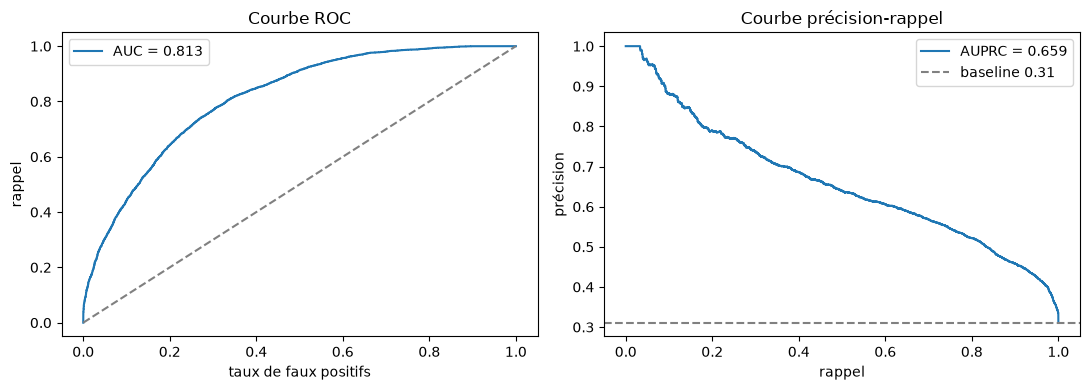

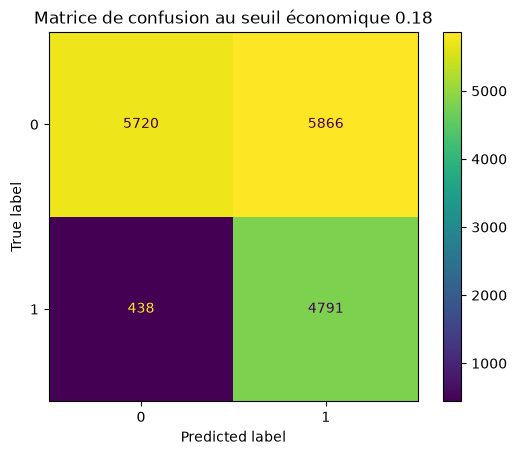

appels déclenchés : 10,657 sur 16,815 | gain espéré : 95,516 €


In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

def pipe_logreg():
    return Pipeline([
        ("features", FunctionTransformer(build_features, validate=False)),
        ("prep", ColumnTransformer([
            ("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), FEATURES_NUM),
            ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                              ("o", OneHotEncoder(handle_unknown="ignore"))]), FEATURES_CAT)])),
        ("modele", LogisticRegression(max_iter=1000)),
    ])

pipe_final = pipe_logreg().fit(X_tr, y_tr)
p_te = pipe_final.predict_proba(X_te)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fpr, tpr, _ = roc_curve(y_te, p_te)
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_te, p_te):.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(title="Courbe ROC", xlabel="taux de faux positifs", ylabel="rappel")
axes[0].legend()
prec, rap, _ = precision_recall_curve(y_te, p_te)
axes[1].plot(rap, prec, label=f"AUPRC = {average_precision_score(y_te, p_te):.3f}")
axes[1].axhline(y_te.mean(), ls="--", color="gray", label=f"baseline {y_te.mean():.2f}")
axes[1].set(title="Courbe précision-rappel", xlabel="rappel", ylabel="précision")
axes[1].legend()
plt.tight_layout(); plt.show()

SEUIL = 0.18
ConfusionMatrixDisplay(confusion_matrix(y_te, p_te >= SEUIL)).plot()
plt.title(f"Matrice de confusion au seuil économique {SEUIL}"); plt.show()

# Gain espéré : p*(100/3) - 6 par appel
pred = p_te >= SEUIL
gain = ((p_te[pred] * 100 / 3) - 6).sum()
print(f"appels déclenchés : {pred.sum():,} sur {len(y_te):,} | gain espéré : {gain:,.0f} €")

## 7. Diagnostic de fitting

L'écart AUPRC train/test (~0,79 vs ~0,65) reste contenu : le train contient les
années « faciles » et un léger sur-ajustement. Ni sous-apprentissage (le modèle
explote bien le signal du délai) ni sur-apprentissage sévère : la courbe
d'apprentissage ci-dessous le confirme.

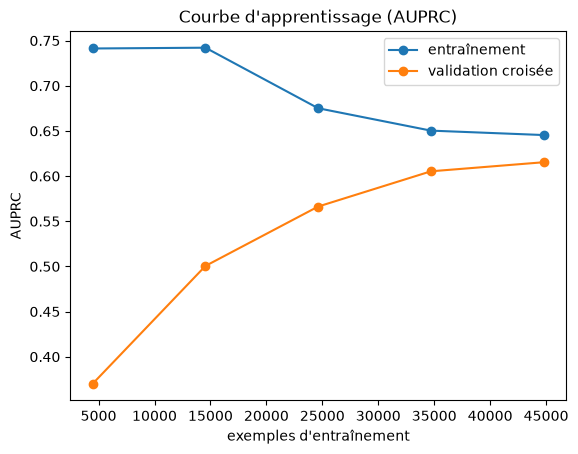

In [11]:
from sklearn.model_selection import learning_curve

tailles, tr, te = learning_curve(
    pipe_logreg(), X_tr, y_tr,
    train_sizes=np.linspace(0.1, 1.0, 5), cv=3,
    scoring="average_precision", n_jobs=-1)
plt.plot(tailles, tr.mean(axis=1), "o-", label="entraînement")
plt.plot(tailles, te.mean(axis=1), "o-", label="validation croisée")
plt.title("Courbe d'apprentissage (AUPRC)")
plt.xlabel("exemples d'entraînement"); plt.ylabel("AUPRC"); plt.legend(); plt.show()

## 8. Interprétation pour un responsable commercial

Les variables qui pèsent le plus (importance par permutation sur le test) :
le **délai entre réservation et arrivée**, la **garantie non remboursable**
(paradoxalement associée à presque toutes les annulations : ces clients annulent
car ils n'ont rien à perdre... ou ces dossiers sont des annulations tarifées),
l'**historique d'annulations** et la **fidélité**, le **canal intermédiaire**
(agences en ligne) et le **site urbain**.

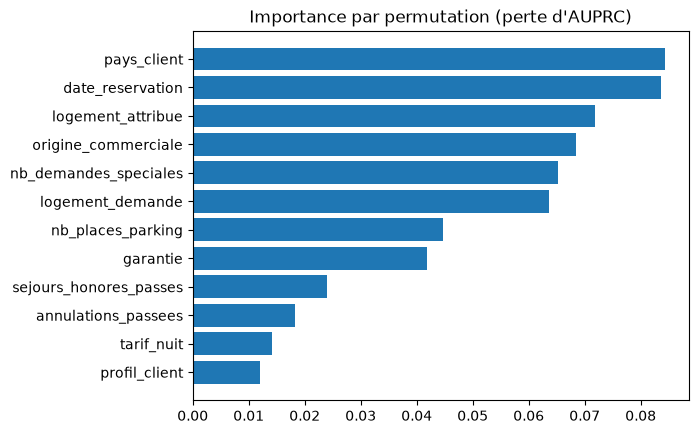

In [12]:
from sklearn.inspection import permutation_importance

sub = X_te.sample(4000, random_state=0)
imp = permutation_importance(pipe_final, sub, y_te.loc[sub.index],
                             n_repeats=3, random_state=0,
                             scoring="average_precision")
noms = X.columns
ordre_imp = np.argsort(imp.importances_mean)[-12:]
plt.barh([noms[i] for i in ordre_imp], imp.importances_mean[ordre_imp])
plt.title("Importance par permutation (perte d'AUPRC)"); plt.show()

## 9. Mise en production

`train.py` réentraîne le même pipeline et l'exporte dans `model.pkl` ;
`app.py` (Gradio) et `api.py` (FastAPI) le chargent et appliquent le seuil 0,18,
réglable dans l'application. Voir `note_methodologique.md`.